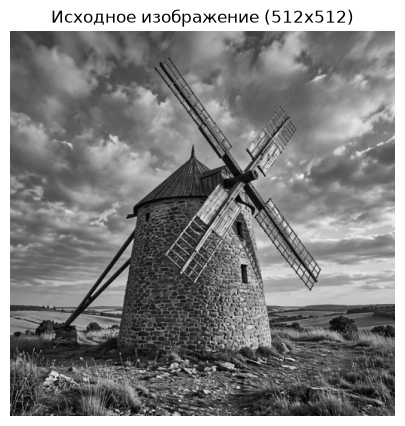

In [11]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

gray_img = cv2.imread("img.jpeg", cv2.IMREAD_GRAYSCALE)
if gray_img is None:
    gray_img = cv2.imread("img.jpeg", cv2.IMREAD_GRAYSCALE)

gray_img = gray_img.astype(np.float64)

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(gray_img, cmap="gray")
ax.set_title(f"Исходное изображение ({gray_img.shape[1]}x{gray_img.shape[0]})")
ax.axis("off")
plt.show()

In [12]:
def haar_transform_2d(block):
    """Один уровень двумерного дискретного вейвлет-преобразования Хаара."""
    h_avg = (block[:, 0::2] + block[:, 1::2]) / 2.0
    h_diff = (block[:, 0::2] - block[:, 1::2]) / 2.0

    LL = (h_avg[0::2, :] + h_avg[1::2, :]) / 2.0
    LH = (h_avg[0::2, :] - h_avg[1::2, :]) / 2.0
    HL = (h_diff[0::2, :] + h_diff[1::2, :]) / 2.0
    HH = (h_diff[0::2, :] - h_diff[1::2, :]) / 2.0

    return np.block([[LL, HL],
                     [LH, HH]])

In [13]:
levels = 3
h, w = gray_img.shape
current_matrix = gray_img.copy()

full_stages = []     
compressed_ll = []    

for step in range(levels):
    sub_h = h // (2 ** step)
    sub_w = w // (2 ** step)

    current_matrix[:sub_h, :sub_w] = haar_transform_2d(current_matrix[:sub_h, :sub_w])
    full_stages.append(current_matrix.copy())

    ll_h, ll_w = sub_h // 2, sub_w // 2
    compressed_ll.append(current_matrix[:ll_h, :ll_w].copy())

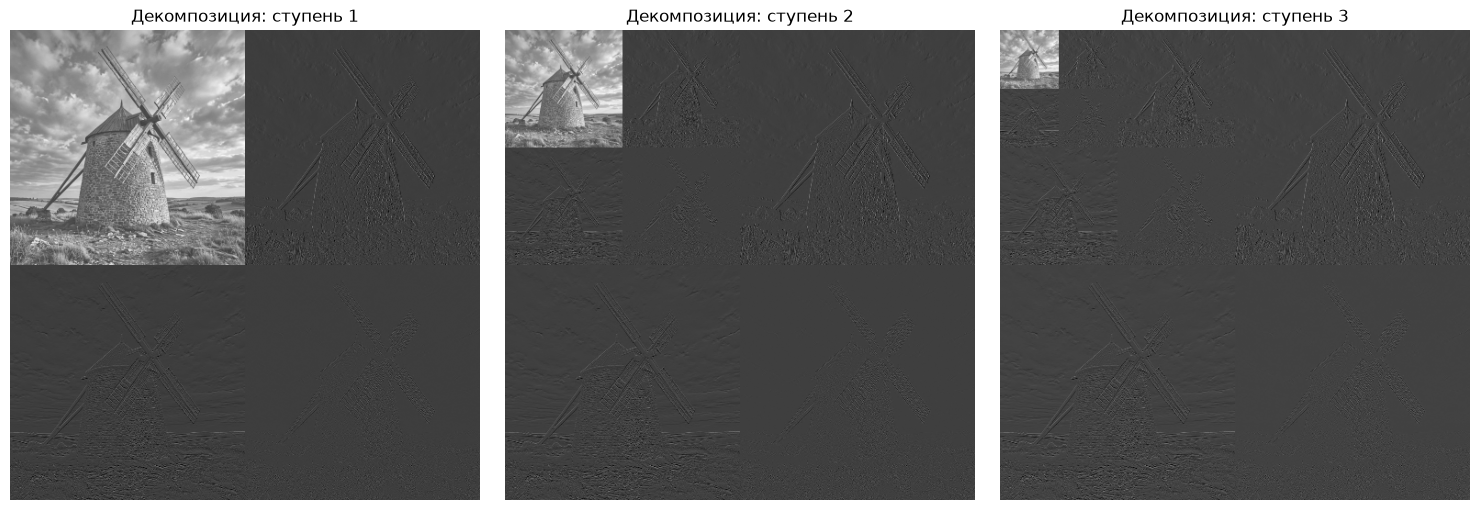

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for idx, stage_img in enumerate(full_stages):
    axes[idx].imshow(stage_img, cmap="gray")
    axes[idx].set_title(f"Декомпозиция: ступень {idx + 1}")
    axes[idx].axis("off")

plt.tight_layout()
plt.show()

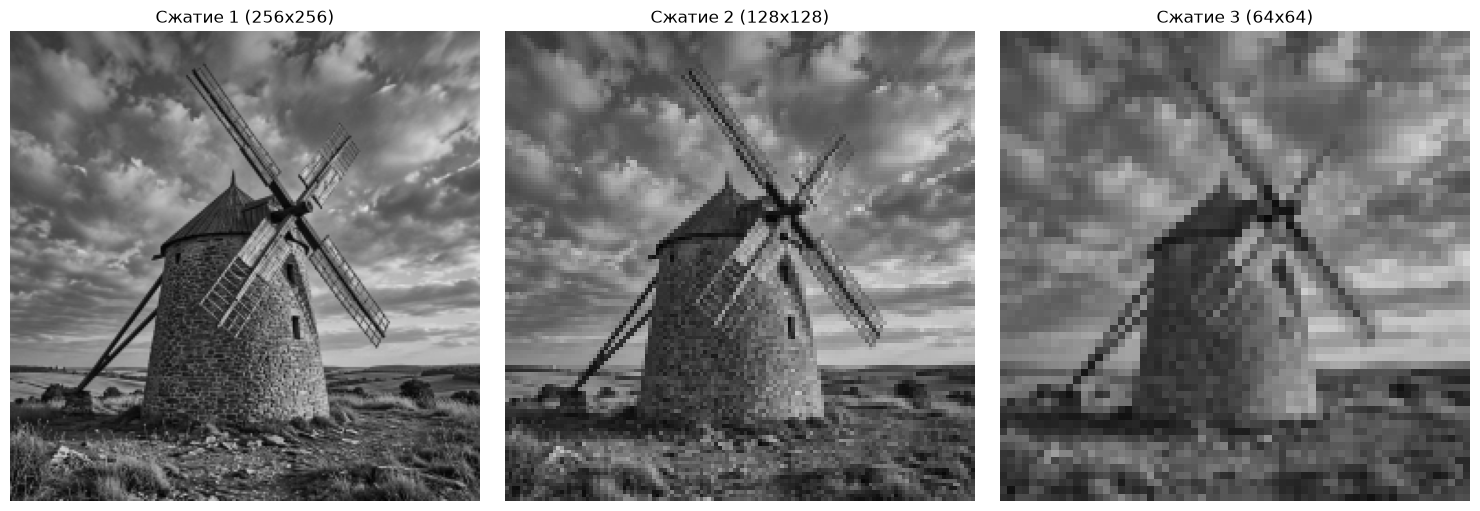

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for idx, ll_img in enumerate(compressed_ll):
    axes[idx].imshow(ll_img, cmap="gray", vmin=0, vmax=255)
    axes[idx].set_title(f"Сжатие {idx + 1} ({ll_img.shape[1]}x{ll_img.shape[0]})")
    axes[idx].axis("off")

plt.tight_layout()
plt.show()